# **ACTIVITY #3 : OBJECT COUNTING (COINS & RGB)**




Image width: 3000px
Image height: 2250px
Number of channels: 3


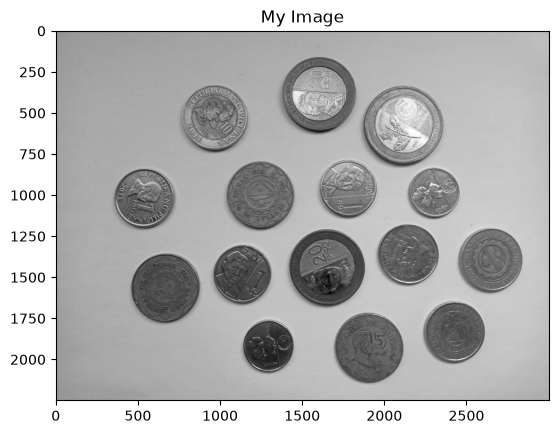

In [201]:
import cv2 
import matplotlib.pyplot as plt

# Load an image (change 'image.jpg' to your image file path)
image = cv2.imread('Coins.jpg')

# Check if the image was loaded properly
if image is None:
    print("Error: Could not load image.")
else:
    # Get the size of the image
    height, width, channels = image.shape #[rows, columns, rbg--> [r,g,b]]
    print(f"Image width: {width}px")
    print(f"Image height: {height}px")
    print(f"Number of channels: {channels}")

    # Show the image in a window
    
    image_g = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    image_gray = cv2.cvtColor(image_g, cv2.COLOR_BGR2RGB)

    # Show the image in the notebook
    plt.imshow(image_gray)
    plt.title("My Image")
    plt.axis('on')  # You can use 'off' to hide axes
    plt.show()


In [202]:
import copy

original = [[1, 2], [3, 4]]
shallow = copy.copy(original)

shallow[0][0] = 99
print(original)  # [[99, 2], [3, 4]]

[[99, 2], [3, 4]]


In [203]:
original = [[1, 2], [3, 4]]
deep = copy.deepcopy(original)

In [204]:
deep[0][0] = 99
print(original)
print(deep)

[[1, 2], [3, 4]]
[[99, 2], [3, 4]]


Detected objects: 15


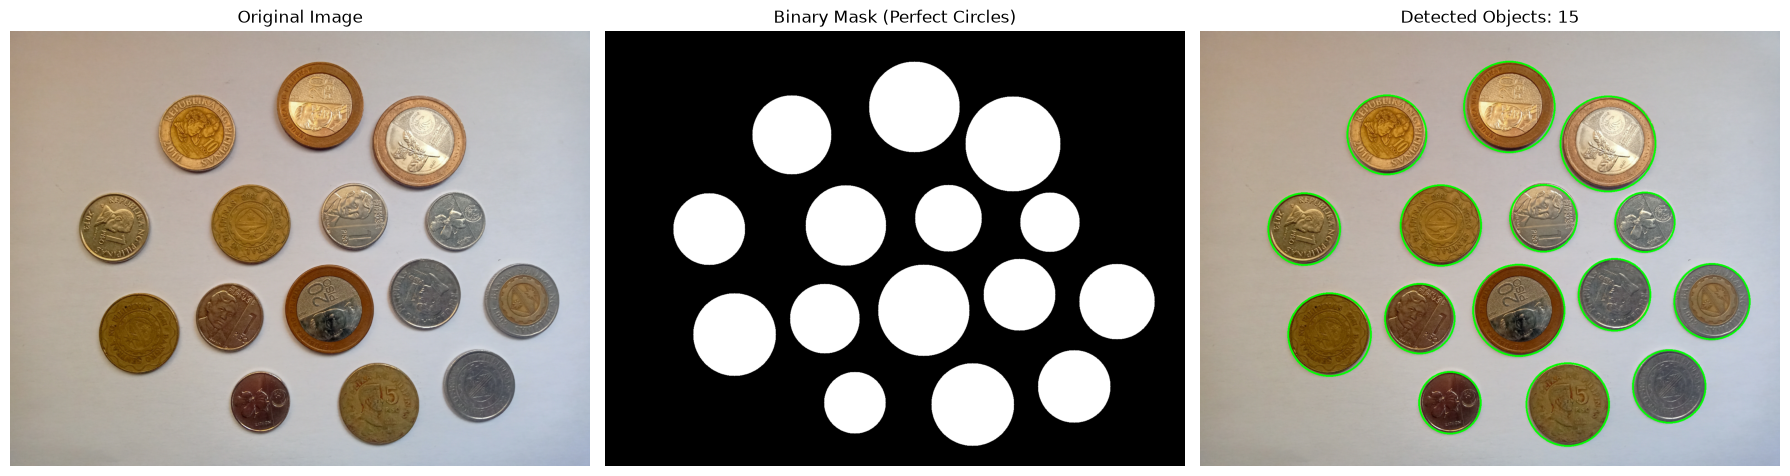

In [205]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load image (replace with your own image path)
image = cv2.imread('Coins.jpg')  # Make sure the image is in your working directory

if image is None:
    print("Error: Could not load image.")
else:
    # Scale down moderately to save memory
    max_dimension = 1600
    h, w = image.shape[:2]
    if max(h, w) > max_dimension:
        scale = max_dimension / float(max(h, w))
        image = cv2.resize(image, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)

    # Convert to RGB and Grayscale
    rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB).astype(np.uint8)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Blur image
    blurred = cv2.GaussianBlur(gray, (9, 9), 2)

    # Apply Otsu's Thresholding
    _, mask = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    # Morphological cleaning
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (11, 11))
    mask_cleaned = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=3)

    # Flood Fill Hole-Filling
    h_mask, w_mask = mask_cleaned.shape
    floodfilled = mask_cleaned.copy()
    flood_mask = np.zeros((h_mask + 2, w_mask + 2), np.uint8)
    cv2.floodFill(floodfilled, flood_mask, (0, 0), 255)
    mask_filled = mask_cleaned | cv2.bitwise_not(floodfilled)

    # Find raw contours
    contours, _ = cv2.findContours(mask_filled, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # OPTIMIZATION: Create a clean black mask canvas for perfect geometric circles
    perfect_binary_mask = np.zeros((h_mask, w_mask), dtype=np.uint8)
    output_image = rgb_image.copy()
    count = 0

    for contour in contours:
        area = cv2.contourArea(contour)
        
        # Filter noise and border artifacts
        if 800 < area < (h_mask * w_mask * 0.8):
            count += 1
            # Compute center and radius for exact circle geometry
            (x, y), radius = cv2.minEnclosingCircle(contour)
            center = (int(x), int(y))
            radius = int(radius)

            # OPTIMIZATION: Draw solid white circle on the binary mask canvas
            cv2.circle(perfect_binary_mask, center, radius, 255, thickness=-1)

            # Draw outer outline on the final image
            cv2.circle(output_image, center, radius, (0, 255, 0), 3)

    print(f"Detected objects: {count}")

    # Plotting images inline
    fig, axs = plt.subplots(1, 3, figsize=(18, 6))

    axs[0].imshow(rgb_image)
    axs[0].set_title("Original Image")
    axs[0].axis('off')

    # Displays the reconstructed perfect circle binary mask
    axs[1].imshow(perfect_binary_mask, cmap='gray')
    axs[1].set_title("Binary Mask (Perfect Circles)")
    axs[1].axis('off')

    axs[2].imshow(output_image)
    axs[2].set_title(f"Detected Objects: {count}")
    axs[2].axis('off')

    plt.tight_layout()
    plt.show()

27052.0
20437.0
29780.0
21704.0
11549.0
17250.0
11073.0
17119.0
18783.0
27519.0
16017.0
22670.0
17357.0
22404.0
12589.0


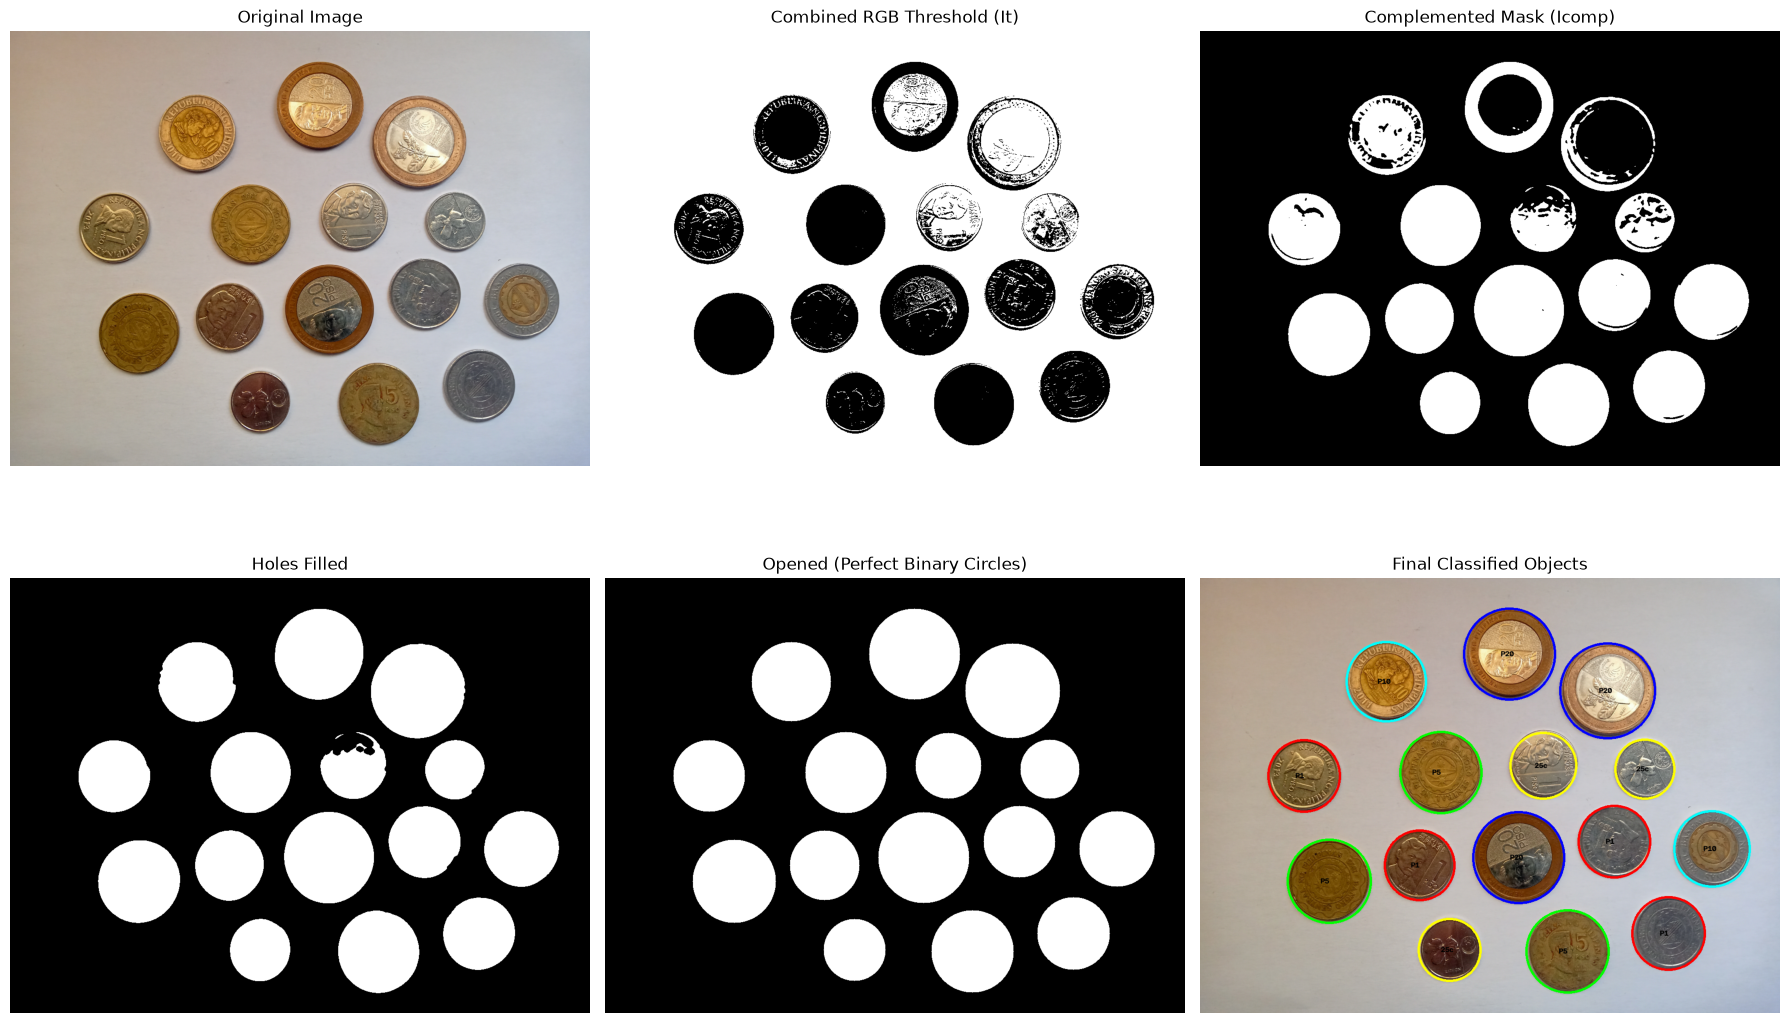

25cents: 3
P1:      4
P5:      3
P10:     2
P20:     3
Total count: 15


In [220]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops
from skimage.morphology import disk, opening

# Load image
image = cv2.imread('Coins.jpg')
if image is None:
    raise FileNotFoundError("Image not found.")

# MEMORY & STABILITY OPTIMIZATION: Downscale image if resolution is too high
max_dimension = 1200
h, w = image.shape[:2]
if max(h, w) > max_dimension:
    scale = max_dimension / float(max(h, w))
    image = cv2.resize(image, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)

# Convert to RGB (uint8 explicitly keeps memory footprint low)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB).astype(np.uint8)

# Extract channels (retained for visualization tracking)
rmat = image_rgb[:, :, 0]
gmat = image_rgb[:, :, 1]
bmat = image_rgb[:, :, 2]

# OPTIMIZATION: Convert to Grayscale & apply Gaussian Blur
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (9, 9), 2)

# Combined RGB Threshold representation for subplot alignment
levelr, levelg, levelb = 0.45 * 255, 0.40 * 255, 0.35 * 255
Ired = (rmat > levelr).astype(np.uint8)
Igreen = (gmat > levelg).astype(np.uint8)
Iblue = (bmat > levelb).astype(np.uint8)
It = cv2.bitwise_and(cv2.bitwise_and(Ired, Igreen), Iblue)

# OPTIMIZATION: Robust Otsu's Thresholding for core segmentation
_, Icomp = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Morphological pre-cleaning (reduced kernel prevents merging adjacent coins)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
Icomp_cleaned = cv2.morphologyEx(Icomp, cv2.MORPH_CLOSE, kernel, iterations=2)

# Fill holes (FloodFill with border padding to avoid edge leaks)
padded = cv2.copyMakeBorder(Icomp_cleaned, 1, 1, 1, 1, cv2.BORDER_CONSTANT, value=0)
flood_fill = padded.copy()
h_f, w_f = flood_fill.shape
mask = np.zeros((h_f + 2, w_f + 2), np.uint8)
cv2.floodFill(flood_fill, mask, (0, 0), 255)
filled_padded = cv2.bitwise_or(padded, cv2.bitwise_not(flood_fill))
filled = filled_padded[1:-1, 1:-1]  # Remove padding

# Morphological open to disconnect slight bridges
opened = opening(filled // 255, disk(6)).astype(np.uint8)

# Label connected components
label_image = label(opened)
regions = regionprops(label_image)

### Debug area outputs
for region in regions:
    area = region.area
    centroid = region.centroid
    print(area)

# Classify objects into 5 size tiers: 25cents < P1 < P5 < P10 < P20
cents25, p1, p5, p10, p20 = [], [], [], [], []

for region in regions:
    area = region.area
    # Ignore tiny noise artifacts
    if area < 500:
        continue
    elif area < 12800:
        cents25.append(region)
    elif area < 17400:
        p1.append(region)
    elif area < 20768:
        p10.append(region)
    elif area < 22700:
        p5.append(region)
    else:
        p20.append(region)

# Create a clean canvas for perfectly reconstructed geometric binary circles
perfect_binary_mask = np.zeros_like(opened)
output_img = image_rgb.copy()

# Category configuration tuple: (list, label_text, RGB_color)
categories = [
    (cents25, '25c', (255, 255, 0)),  # Yellow
    (p1,      'P1',  (255, 0, 0)),    # Red
    (p5,      'P5',  (0, 255, 0)),    # Green
    (p10,     'P10', (0, 255, 255)),  # Cyan
    (p20,     'P20', (0, 0, 255))     # Blue
]

# Draw classification circles and text labels
for category, label_text, color in categories:
    for region in category:
        coords = region.coords
        pts = np.array([[c[1], c[0]] for c in coords], dtype=np.int32)
        (x, y), radius = cv2.minEnclosingCircle(pts)
        center = (int(x), int(y))
        radius = int(radius)

        # Draw smooth filled circle on binary mask
        cv2.circle(perfect_binary_mask, center, radius, 255, thickness=-1)

        # Draw circle and category text label on output image
        cv2.circle(output_img, center, radius, color, 3)
        cv2.putText(output_img, label_text, (center[0] - 18, center[1] + 5), 
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 2)

# Display results side-by-side in 2x3 grid
fig, axs = plt.subplots(2, 3, figsize=(18, 12))

axs[0, 0].imshow(image_rgb)
axs[0, 0].set_title("Original Image")
axs[0, 0].axis("off")

axs[0, 1].imshow(It, cmap='gray')
axs[0, 1].set_title("Combined RGB Threshold (It)")
axs[0, 1].axis("off")

axs[0, 2].imshow(Icomp, cmap='gray')
axs[0, 2].set_title("Complemented Mask (Icomp)")
axs[0, 2].axis("off")

axs[1, 0].imshow(filled, cmap='gray')
axs[1, 0].set_title("Holes Filled")
axs[1, 0].axis("off")

axs[1, 1].imshow(perfect_binary_mask, cmap='gray')
axs[1, 1].set_title("Opened (Perfect Binary Circles)")
axs[1, 1].axis("off")

axs[1, 2].imshow(output_img)
axs[1, 2].set_title("Final Classified Objects")
axs[1, 2].axis("off")

plt.tight_layout()
plt.show()

# Display total count & detailed breakdown
total_count = len(cents25) + len(p1) + len(p5) + len(p10) + len(p20)
print(f"25cents: {len(cents25)}")
print(f"P1:      {len(p1)}")
print(f"P5:      {len(p5)}")
print(f"P10:     {len(p10)}")
print(f"P20:     {len(p20)}")
print(f"Total count: {total_count}")

In [226]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops
from skimage.morphology import disk, opening
from skimage.util import invert

# Load image
image = cv2.imread('Coins.jpg')  # Make sure the image is in your working directory

if image is None:
    print("Error: Could not load image.")
else:
    # Scale down moderately to save memory
    max_dimension = 1600
    h, w = image.shape[:2]
    if max(h, w) > max_dimension:
        scale = max_dimension / float(max(h, w))
        image = cv2.resize(image, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)

# Convert to RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

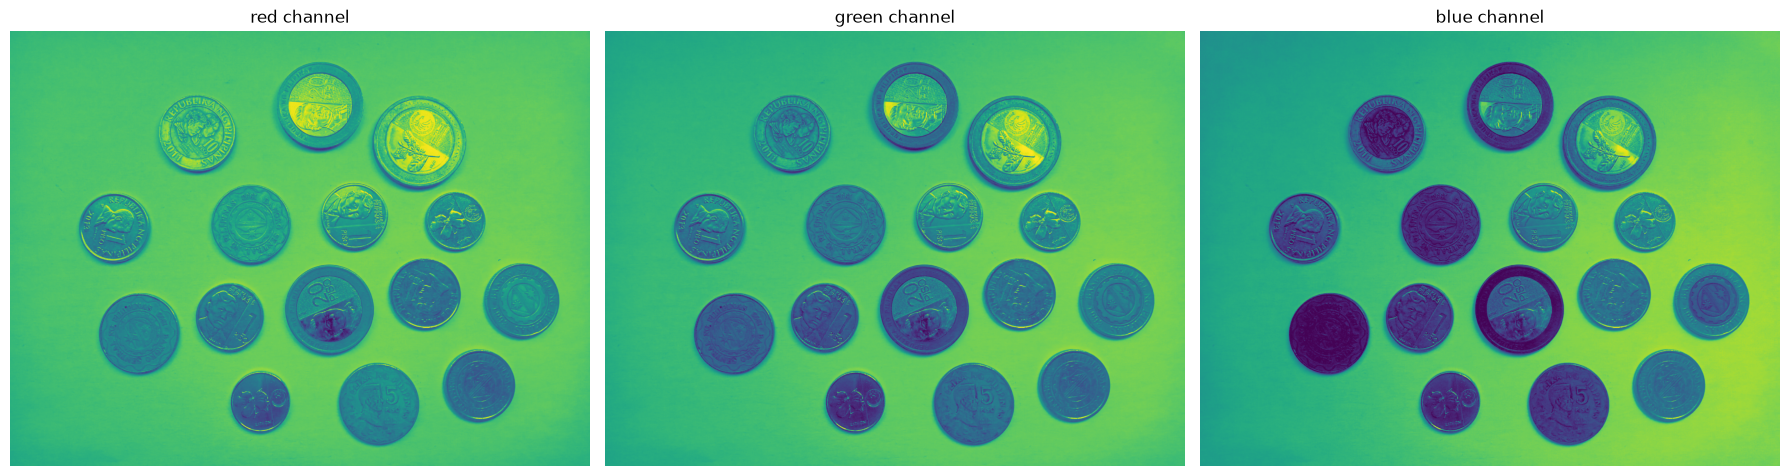

In [227]:
# Extract channels
rmat = image_rgb[:, :, 0]
gmat = image_rgb[:, :, 1]
bmat = image_rgb[:, :, 2]
#show image for each channel
fig, axs = plt.subplots(1, 3, figsize=(18, 12))
axs[0].imshow(rmat)
axs[0].set_title("red channel")
axs[0].axis("off")

axs[1].imshow(gmat)
axs[1].set_title("green channel")
axs[1].axis("off")

axs[2].imshow(bmat)
axs[2].set_title("blue channel")
axs[2].axis("off")

plt.tight_layout()
plt.show()

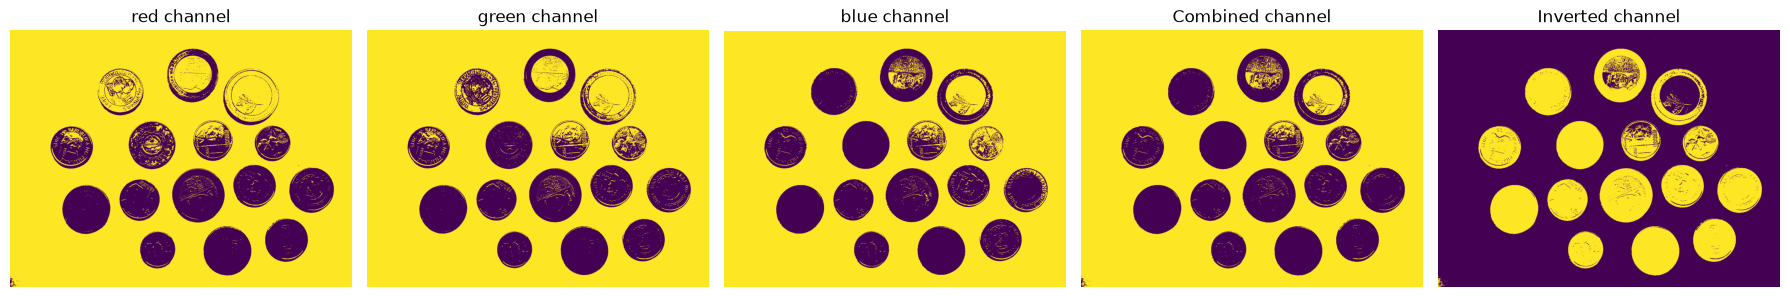

In [228]:
# Threshold levels
levelr = 0.60* 255
levelg = 0.50 * 255
levelb = 0.45 * 255

# Threshold RGB channels
Ired = (rmat > levelr).astype(np.uint8)
Igreen = (gmat > levelg).astype(np.uint8)
Iblue = (bmat > levelb).astype(np.uint8)

# Combine channels
It = cv2.bitwise_and(cv2.bitwise_and(Ired, Igreen), Iblue)

# Invert mask
Icomp = cv2.bitwise_not(It * 255)

#show image for each channel
fig, axs = plt.subplots(1, 5, figsize=(18, 12))
axs[0].imshow(Ired)
axs[0].set_title("red channel")
axs[0].axis("off")

axs[1].imshow(Igreen)
axs[1].set_title("green channel")
axs[1].axis("off")

axs[2].imshow(Iblue)
axs[2].set_title("blue channel")
axs[2].axis("off")

axs[3].imshow(It)
axs[3].set_title("Combined channel")
axs[3].axis("off")

axs[4].imshow(Icomp)
axs[4].set_title("Inverted channel")
axs[4].axis("off")

plt.tight_layout()
plt.show()

In [210]:
print(rmat)

[[157 162 163 ... 174 172 173]
 [163 162 163 ... 176 175 176]
 [162 163 162 ... 177 176 177]
 ...
 [154 152 150 ... 160 158 157]
 [154 153 152 ... 158 157 154]
 [153 153 152 ... 160 161 160]]


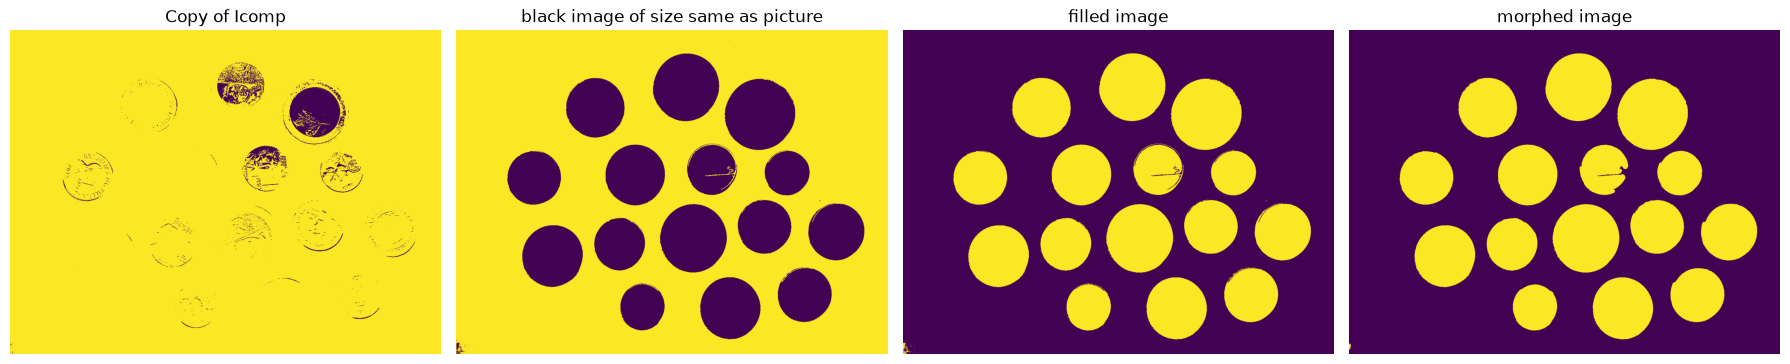

48055.0
37433.0
53710.0
38889.0
24556.0
21277.0
31070.0
30928.0
33916.0
48993.0
28357.0
40439.0
31244.0
40332.0
22055.0
141.0


In [229]:
# Fill holes
flood_fill = Icomp.copy()
h, w = flood_fill.shape
mask = np.zeros((h+2, w+2), np.uint8)
cv2.floodFill(flood_fill, mask, (0, 0), 255)
filled = cv2.bitwise_or(Icomp, cv2.bitwise_not(flood_fill))

# Morphological open
opened = opening(filled // 255, disk(6)).astype(np.uint8)

# Label connected components
label_image = label(opened)
regions = regionprops(label_image)

#show image for each channel
fig, axs = plt.subplots(1, 4, figsize=(18, 12))
axs[0].imshow(flood_fill)
axs[0].set_title("Copy of Icomp")
axs[0].axis("off")

axs[1].imshow(mask)
axs[1].set_title("black image of size same as picture")
axs[1].axis("off")

axs[2].imshow(filled)
axs[2].set_title("filled image")
axs[2].axis("off")

axs[3].imshow(opened)
axs[3].set_title("morphed image")
axs[3].axis("off")


plt.tight_layout()
plt.show()
###
for region in regions:
        area = region.area
        print(area)

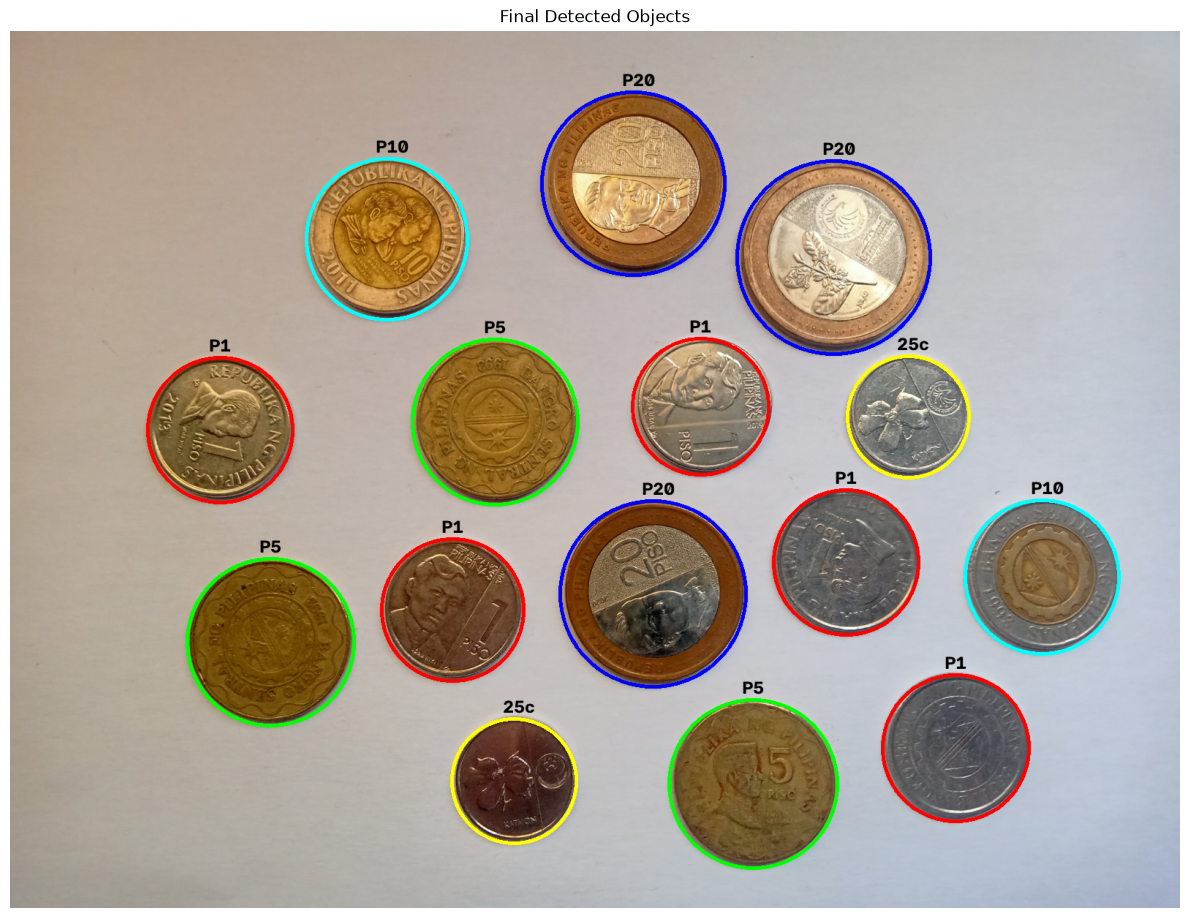

25cents: 2
P1:      5
P5:      3
P10:     2
P20:     3
count:   15


In [240]:
# Category lists: 25c < P1 < P5 < P10 < P20
cents25, p1, p5, p10, p20 = [], [], [], [], []

for region in regions:
    area = region.area
    if area < 500:
        continue
    elif area < 23000:
        cents25.append(region)   
    elif area < 33000:
        p1.append(region)        
    elif area < 38000:
        p10.append(region)       
    elif area < 48000:
        p5.append(region)       
    else:
        p20.append(region)      

# Draw bounding boxes and text labels
output_img = image_rgb.copy()

categories = [
    (cents25, '25c', (255, 255, 0)),  # Yellow
    (p1,      'P1',  (255, 0, 0)),    # Red
    (p5,      'P5',  (0, 255, 0)),    # Green
    (p10,     'P10', (0, 255, 255)),  # Cyan
    (p20,     'P20', (0, 0, 255))     # Blue
]

for category, label_text, color in categories:
    for region in category:
        # Calculate center and radius using region properties
        cy, cx = map(int, region.centroid)
        minr, minc, maxr, maxc = region.bbox
        radius = int(max((maxr - minr), (maxc - minc)) / 2)
        
        # Draw circle and text
        cv2.circle(output_img, (cx, cy), radius, color, 3)
        cv2.putText(output_img, label_text, (cx - 15, cy - radius - 8), 
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 0, 0), 2)

# Display final detection image
fig, axs = plt.subplots(1, 1, figsize=(12, 10))
axs.imshow(output_img)
axs.set_title("Final Detected Objects")
axs.axis("off")

plt.tight_layout()
plt.show()

# Display total counts and detailed breakdown
total_value = len(cents25) + len(p1) + len(p5) + len(p10) + len(p20)
print(f"25cents: {len(cents25)}")
print(f"P1:      {len(p1)}")
print(f"P5:      {len(p5)}")
print(f"P10:     {len(p10)}")
print(f"P20:     {len(p20)}")
print(f"count:   {total_value}")